# Experiment 5: Gray-scale Image Compression using SVD
**Signal Processing and Systems Design Laboratory (EE69205)**

This notebook implements whole-image and patch-wise SVD compression, computes MSE/PSNR/SSIM, plots metric-versus-compression-ratio curves, and compares both approaches.

**Image note:** The lab manual links to a Cameraman image. The notebook first attempts to download that image; if unavailable, it uses `skimage.data.camera()` (a standard 512×512 Cameraman image). The experiment uses a 140×140 crop so it can be divided into 25 patches of 28×28 pixels.


In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from skimage import data, img_as_float
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity

np.random.seed(0)
plt.rcParams["figure.figsize"] = (6, 5)
plt.rcParams["image.cmap"] = "gray"


## 1. Read and display the grayscale Cameraman image

Image source: Lab-manual linked image
Full image shape: (148, 180)


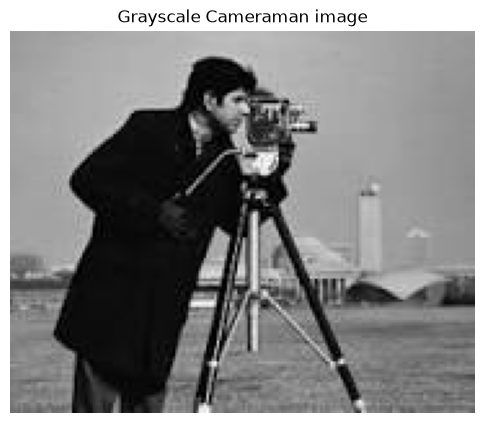

In [2]:
# Try the image linked in the lab manual. Fall back to scikit-image's Cameraman image.
image_url = "https://drive.google.com/uc?export=download&id=1nlTgGDd0dLn5Kg7ZvcW8CEHwnyzH-tFW"
download_path = "cameraman_lab.png"

try:
    urllib.request.urlretrieve(image_url, download_path)
    original_full = np.asarray(Image.open(download_path).convert("L"), dtype=np.float64) / 255.0
    image_source = "Lab-manual linked image"
except Exception as exc:
    original_full = img_as_float(data.camera())
    image_source = "skimage.data.camera() fallback"

print(f"Image source: {image_source}")
print(f"Full image shape: {original_full.shape}")
plt.imshow(original_full, vmin=0, vmax=1)
plt.title("Grayscale Cameraman image")
plt.axis("off")
plt.show()


## 2. Crop to 140 × 140 pixels

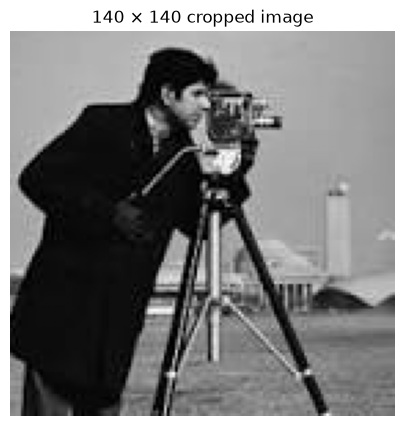

Cropped image shape: (140, 140)


In [3]:
H = W = 140
if original_full.shape[0] < H or original_full.shape[1] < W:
    raise ValueError("Input image must be at least 140×140 pixels.")
# Center 140×140 crop, as requested.
start_row = (original_full.shape[0] - H) // 2
start_col = (original_full.shape[1] - W) // 2
image = original_full[start_row:start_row + H, start_col:start_col + W]
plt.imshow(image, vmin=0, vmax=1)
plt.title("140 × 140 cropped image")
plt.axis("off")
plt.show()
print("Cropped image shape:", image.shape)


## 3. Helper functions and SVD decomposition

For an image matrix \(A\), the rank-\(K\) approximation is
\(A_K = \sum_{k=1}^{K} s_k u_k v_k^T\).

The lab manual defines compression ratio as the number of retained parameters divided by the original pixel count:
\[
CR = \frac{K(1+H+W)}{HW}.
\]
MSE is lower-is-better, while PSNR and SSIM are higher-is-better. Pixel values are normalized to [0, 1], so the metrics use `data_range=1`.


K = 140 reconstruction metrics


,MSE,PSNR (dB),SSIM
K=140,1.109504e-30,299.54871,1.0


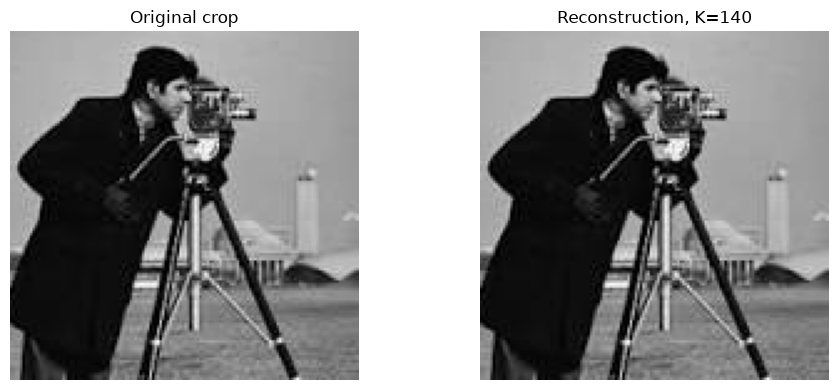

In [4]:
def svd_reconstruct(matrix, k):
    U, s, Vt = np.linalg.svd(matrix, full_matrices=False)
    return (U[:, :k] * s[:k]) @ Vt[:k, :]

def calculate_metrics(reference, estimate):
    return {
        "MSE": mean_squared_error(reference, estimate),
        "PSNR (dB)": peak_signal_noise_ratio(reference, estimate, data_range=1.0),
        "SSIM": structural_similarity(reference, estimate, data_range=1.0)
    }

def image_compression_ratio(k, height, width):
    return k * (1 + height + width) / (height * width)

U, singular_values, Vt = np.linalg.svd(image, full_matrices=False)
reconstructed_140 = (U[:, :140] * singular_values[:140]) @ Vt[:140, :]
metrics_full_rank = calculate_metrics(image, reconstructed_140)
print("K = 140 reconstruction metrics")
display(pd.DataFrame([metrics_full_rank], index=["K=140"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(image, vmin=0, vmax=1); ax[0].set_title("Original crop"); ax[0].axis("off")
ax[1].imshow(np.clip(reconstructed_140, 0, 1), vmin=0, vmax=1); ax[1].set_title("Reconstruction, K=140"); ax[1].axis("off")
plt.tight_layout(); plt.show()


## 4. Whole-image compression for K = 5, 10, 20, 40, 50, 100

,K,CR,MSE,PSNR (dB),SSIM
0,5,0.071684,0.014199,18.477274,0.477560
1,10,0.143367,0.007549,21.220962,0.594843
2,20,0.286735,0.002746,25.613745,0.745515
3,40,0.573469,0.000633,31.985802,0.883970
4,50,0.716837,0.000299,35.237253,0.928474
5,100,1.433673,0.000001,58.919715,0.999375


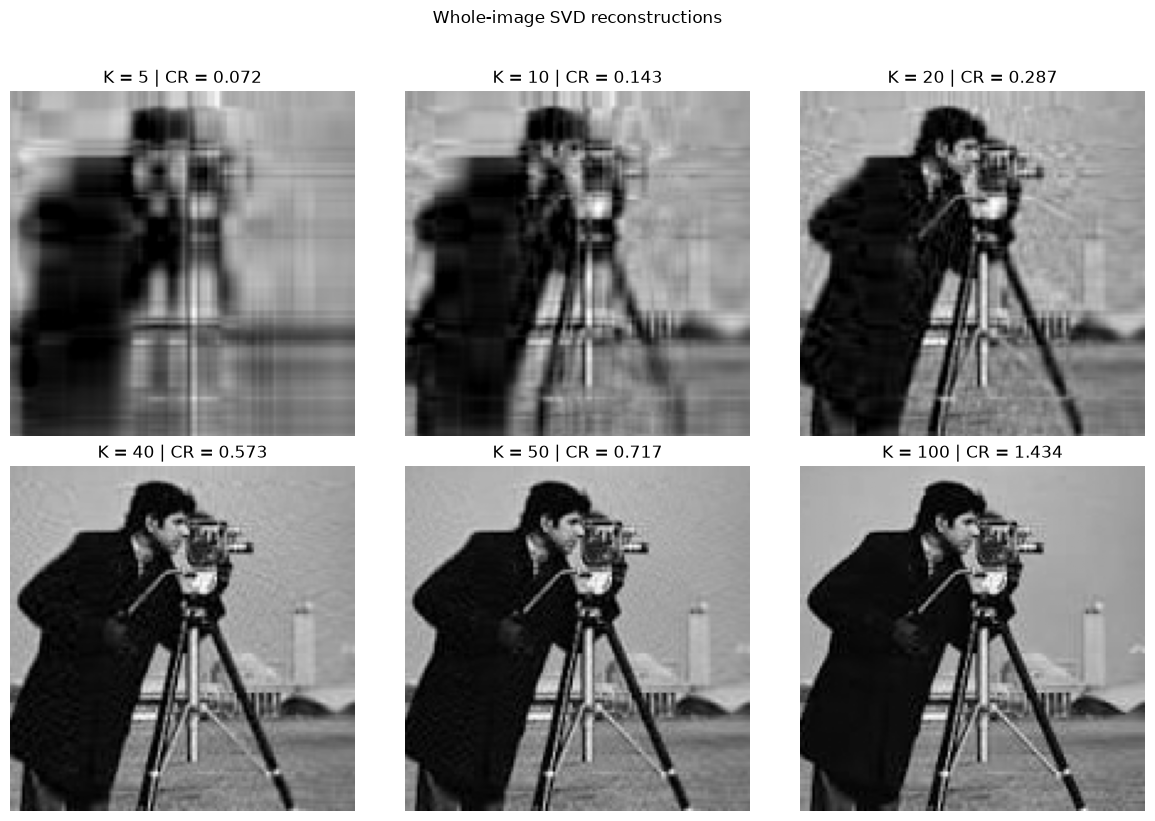

In [5]:
whole_k_values = [5, 10, 20, 40, 50, 100]
whole_results = []
whole_reconstructions = {}

for k in whole_k_values:
    reconstructed = svd_reconstruct(image, k)
    whole_reconstructions[k] = reconstructed
    row = {"K": k, "CR": image_compression_ratio(k, H, W)}
    row.update(calculate_metrics(image, reconstructed))
    whole_results.append(row)

whole_df = pd.DataFrame(whole_results)
display(whole_df.round(6))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, k in zip(axes.flat, whole_k_values):
    ax.imshow(np.clip(whole_reconstructions[k], 0, 1), vmin=0, vmax=1)
    ax.set_title(f"K = {k} | CR = {image_compression_ratio(k,H,W):.3f}")
    ax.axis("off")
plt.suptitle("Whole-image SVD reconstructions", y=1.02)
plt.tight_layout(); plt.show()


## 5. Whole-image metric curves versus compression ratio

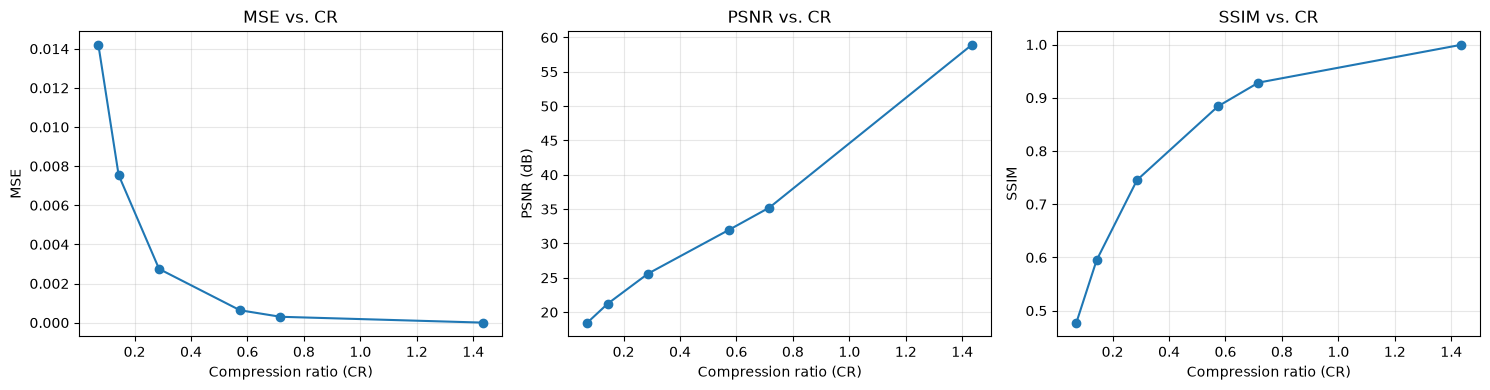

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["MSE", "PSNR (dB)", "SSIM"],
    ["MSE vs. CR", "PSNR vs. CR", "SSIM vs. CR"]
):
    ax.plot(whole_df["CR"], whole_df[metric], marker="o")
    ax.set_xlabel("Compression ratio (CR)")
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 6. Patch-wise compression

The 140×140 crop is split into 25 non-overlapping 28×28 patches. Each patch is compressed independently for \(K = 5, 10, 15, 20\), then reassembled into a 140×140 image. The patch compression ratio follows the lab manual:
\[
CR_p = \frac{K(1+H_p+W_p)}{H_pW_p}.
\]


Number of patches: 25; each patch shape: (28, 28)


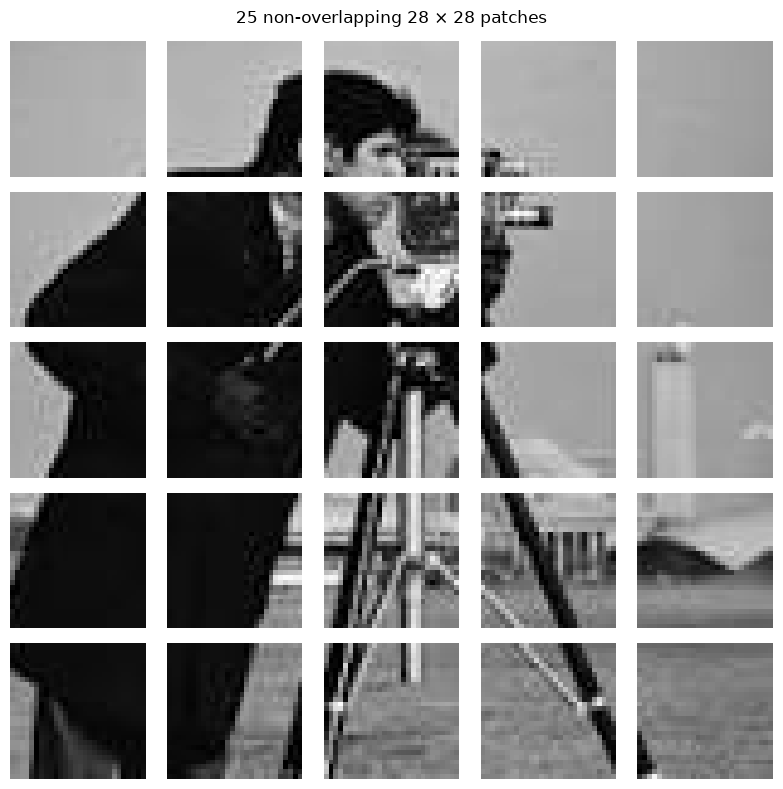

In [7]:
patch_size = 28
patches = [
    image[r:r+patch_size, c:c+patch_size]
    for r in range(0, H, patch_size)
    for c in range(0, W, patch_size)
]
assert len(patches) == 25 and all(p.shape == (28, 28) for p in patches)
print(f"Number of patches: {len(patches)}; each patch shape: {patches[0].shape}")

fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for ax, patch in zip(axes.flat, patches):
    ax.imshow(patch, vmin=0, vmax=1)
    ax.axis("off")
plt.suptitle("25 non-overlapping 28 × 28 patches")
plt.tight_layout(); plt.show()


,K,CRp,MSE,PSNR (dB),SSIM
0,5,0.363520,0.001889,27.237070,0.886467
1,10,0.727041,0.000311,35.070831,0.973961
2,15,1.090561,0.000048,43.166881,0.996108
3,20,1.454082,0.000003,54.881640,0.999773


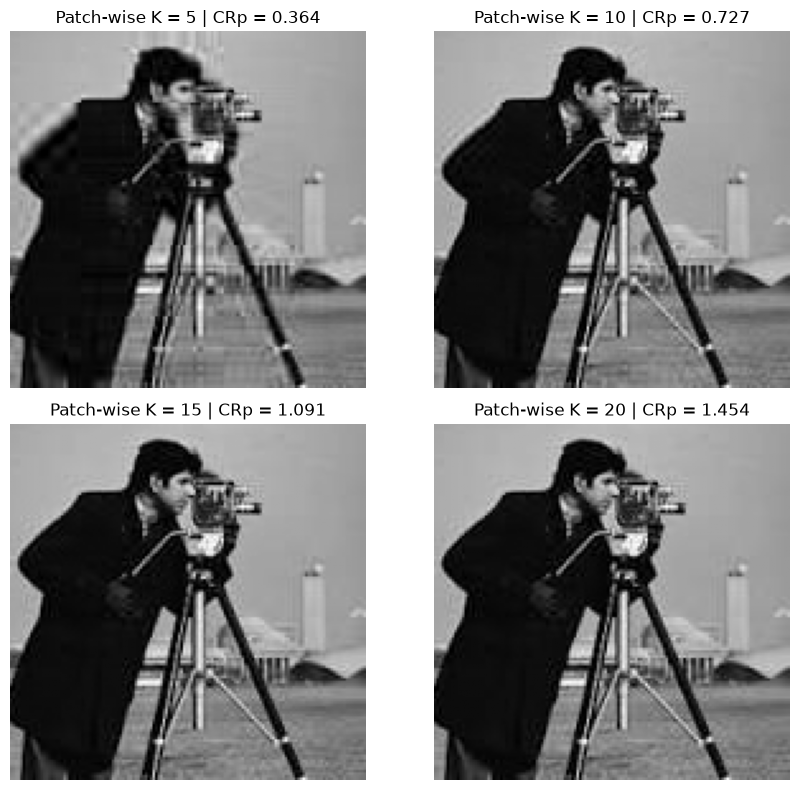

In [8]:
patch_k_values = [5, 10, 15, 20]
patch_results = []
patch_reconstructions = {}

for k in patch_k_values:
    reconstructed_patches = [svd_reconstruct(patch, k) for patch in patches]
    reconstructed_image = np.zeros_like(image)
    idx = 0
    for r in range(0, H, patch_size):
        for c in range(0, W, patch_size):
            reconstructed_image[r:r+patch_size, c:c+patch_size] = reconstructed_patches[idx]
            idx += 1
    patch_reconstructions[k] = reconstructed_image
    row = {"K": k, "CRp": image_compression_ratio(k, patch_size, patch_size)}
    row.update(calculate_metrics(image, reconstructed_image))
    patch_results.append(row)

patch_df = pd.DataFrame(patch_results)
display(patch_df.round(6))

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, k in zip(axes.flat, patch_k_values):
    ax.imshow(np.clip(patch_reconstructions[k], 0, 1), vmin=0, vmax=1)
    ax.set_title(f"Patch-wise K = {k} | CRp = {image_compression_ratio(k,28,28):.3f}")
    ax.axis("off")
plt.tight_layout(); plt.show()


## 7. Patch-wise metric curves versus patch compression ratio

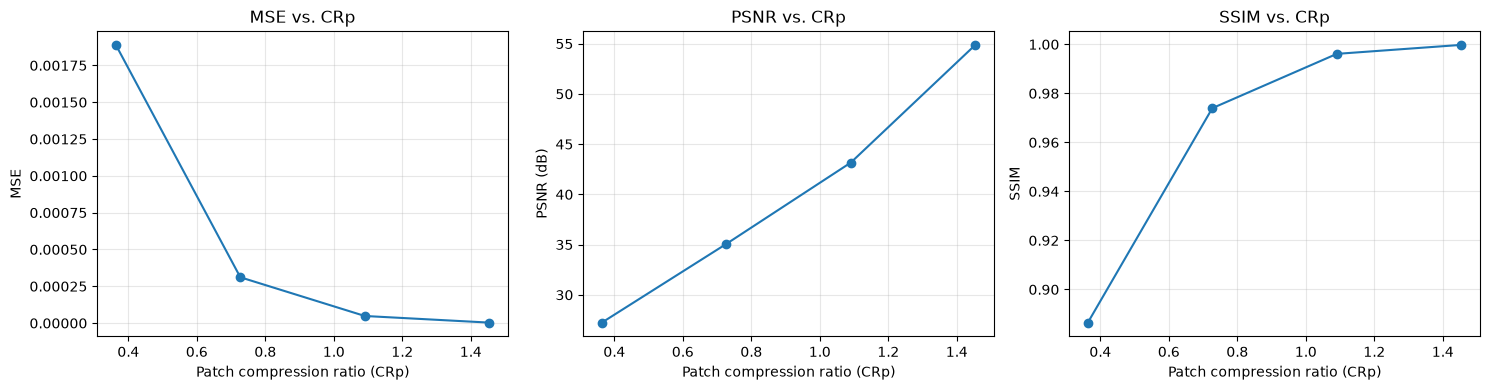

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["MSE", "PSNR (dB)", "SSIM"],
    ["MSE vs. CRp", "PSNR vs. CRp", "SSIM vs. CRp"]
):
    ax.plot(patch_df["CRp"], patch_df[metric], marker="o")
    ax.set_xlabel("Patch compression ratio (CRp)")
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()


## 8. Performance comparison: whole-image vs patch-wise

,Method,K,CR,MSE,PSNR (dB),SSIM
6,Patch-wise,5,0.363520,0.001889,27.237070,0.886467
7,Patch-wise,10,0.727041,0.000311,35.070831,0.973961
8,Patch-wise,15,1.090561,0.000048,43.166881,0.996108
9,Patch-wise,20,1.454082,0.000003,54.881640,0.999773
0,Whole-image,5,0.071684,0.014199,18.477274,0.477560
1,Whole-image,10,0.143367,0.007549,21.220962,0.594843
2,Whole-image,20,0.286735,0.002746,25.613745,0.745515
3,Whole-image,40,0.573469,0.000633,31.985802,0.883970
4,Whole-image,50,0.716837,0.000299,35.237253,0.928474
5,Whole-image,100,1.433673,0.000001,58.919715,0.999375


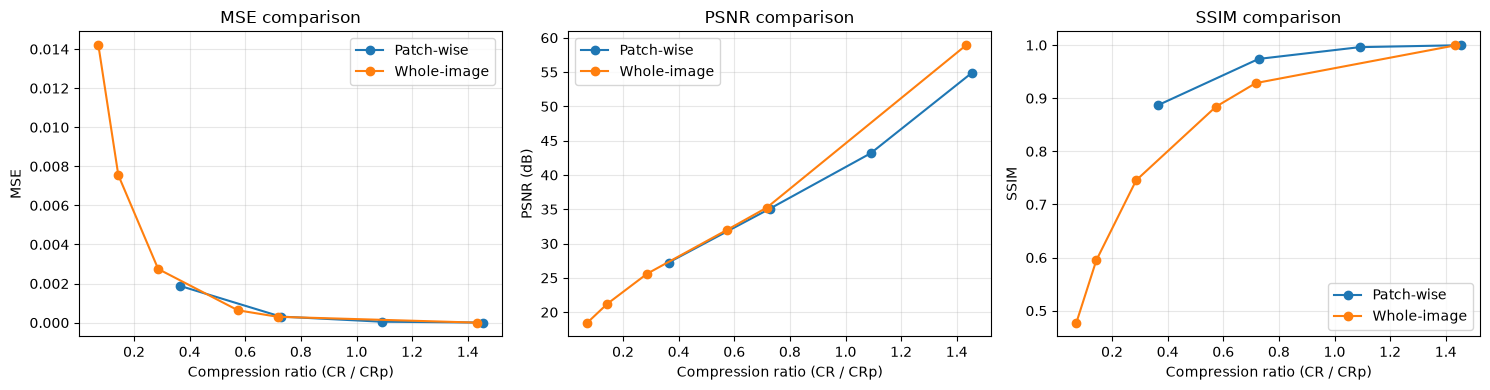

In [10]:
comparison = pd.concat([
    whole_df.assign(Method="Whole-image"),
    patch_df.rename(columns={"CRp": "CR"}).assign(Method="Patch-wise")
], ignore_index=True)
comparison = comparison[["Method", "K", "CR", "MSE", "PSNR (dB)", "SSIM"]]
display(comparison.sort_values(["Method", "K"]).round(6))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["MSE", "PSNR (dB)", "SSIM"],
    ["MSE comparison", "PSNR comparison", "SSIM comparison"]
):
    for method, group in comparison.groupby("Method"):
        ax.plot(group["CR"], group[metric], marker="o", label=method)
    ax.set_xlabel("Compression ratio (CR / CRp)")
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout(); plt.show()


## 9. Observations and conclusion

Use the tables and plots above to support the following observations:

1. Increasing \(K\) retains more singular components and generally improves reconstruction quality: MSE decreases, while PSNR and SSIM increase.
2. At \(K=140\), the crop is reconstructed to numerical precision because all singular components are retained (small nonzero error may remain due to floating-point arithmetic).
3. Patch-wise compression applies a separate low-rank approximation to each 28×28 region. It can preserve local structure differently from a single low-rank approximation of the whole image, but the outcome depends on the image content and the selected \(K\).
4. The reported compression ratios follow the formulas in the lab manual. These are parameter-count ratios and do not include file-format or encoding overhead.
5. Compare the actual metric values in the tables before stating which method performs better at a particular compression ratio; do not assume patch-wise compression is always superior.

**Submission note:** The lab manual also asks for a separate PDF report. This notebook completes the requested code and visualization work; a report can be prepared separately from the observed results.


## 10. Final image assembly from all cropped patches

This final step explicitly assembles the 25 original 28×28 crops into one 140×140 image, then displays the full assembled reconstruction for each patch-wise SVD rank. The tiled patch layout preserves the original patch positions.

Original crop and assembled patch image match: True


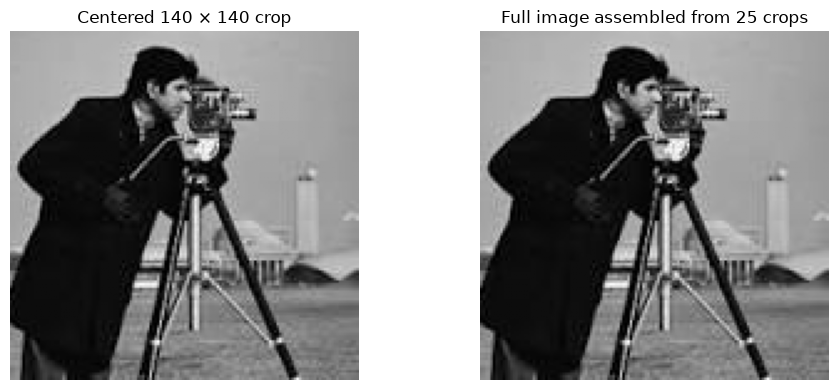

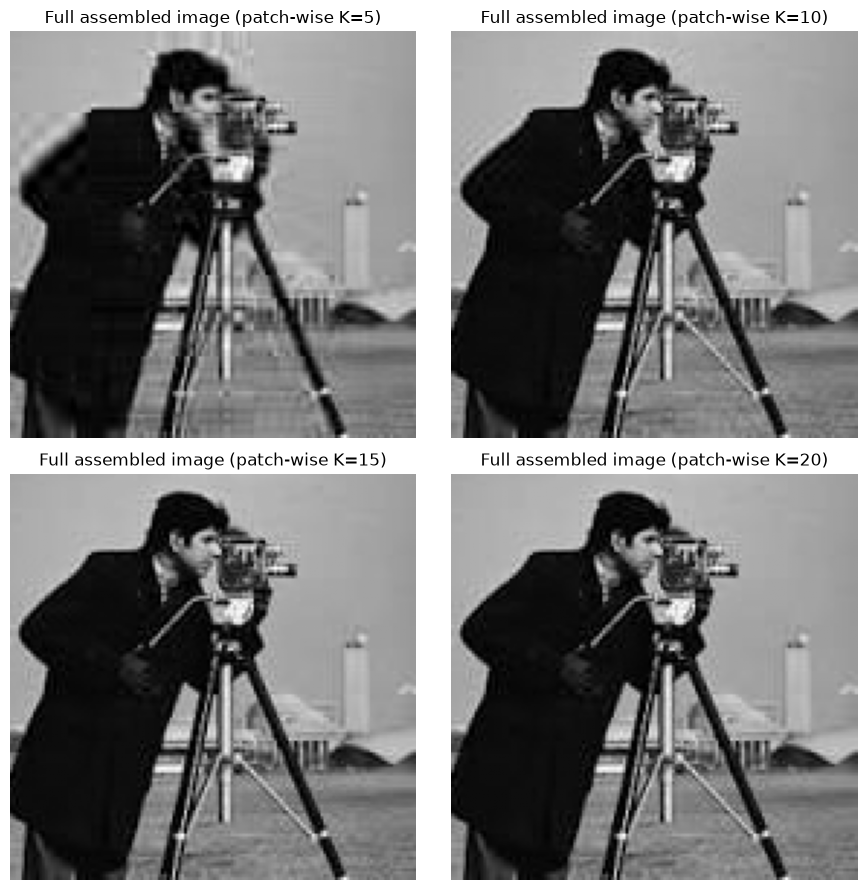

In [11]:
# Reassemble the original 25 cropped patches to verify the tiling order.
assembled_original = np.zeros_like(image)
idx = 0
for r in range(0, H, patch_size):
    for c in range(0, W, patch_size):
        assembled_original[r:r+patch_size, c:c+patch_size] = patches[idx]
        idx += 1

print("Original crop and assembled patch image match:",
      np.allclose(image, assembled_original))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(image, vmin=0, vmax=1)
axes[0].set_title("Centered 140 × 140 crop")
axes[0].axis("off")
axes[1].imshow(assembled_original, vmin=0, vmax=1)
axes[1].set_title("Full image assembled from 25 crops")
axes[1].axis("off")
plt.tight_layout()
plt.show()

# Show each complete image assembled from its 25 reconstructed patches.
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, k in zip(axes.flat, patch_k_values):
    ax.imshow(np.clip(patch_reconstructions[k], 0, 1), vmin=0, vmax=1)
    ax.set_title(f"Full assembled image (patch-wise K={k})")
    ax.axis("off")
plt.tight_layout()
plt.show()
